# Ioannou_Georgios


<h1 align="center"> Decision Trees (DT) and Random Forests (RF) Exercise </h1>
    

<p style="text-align:center;">Run this notebook from top to bottom. In each <b style="color:#E67E22;">Your turn</b> cell, write your code under the comment.</p>


<h2 align="center"> Libraries </h2>


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


In [2]:
%pip install matplotlib seaborn graphviz scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 24.2 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 34.9 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 34.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 35.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 34.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 36.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 34.3 MB/s  0:00:016m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [seaborn]6/17 [seaborn]ib]n]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# import libraries.

# Use inline so our visualizations display in notebook.

%matplotlib inline

import graphviz                 # graphviz for visualizing our tree.
import matplotlib.pyplot as plt # matplotlib for visualization.
import numpy as np              # numpy for data wrangling.
import pandas as pd             # pandas for data wrangling.
import seaborn as sns           # seaborn for visualization.
sns.set()


from sklearn.tree import DecisionTreeClassifier      # import our Decision Tree.
from sklearn.model_selection import GridSearchCV     # helper function for hyper-parameter turning.
from sklearn.ensemble import RandomForestClassifier  # import our Random Forest.
from sklearn.model_selection import train_test_split # helper function to split our data.
from sklearn import tree                             # import the trees from sklearn.
# helper fuctions to evaluate our model.
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score


<h2 align="center"> Remember our main steps motto "ISBE". </h2>

<h3 align="center"> Main Steps when building a Machine Learning Model. </h3>

1. <b>I</b> - Inspect and explore data.
2. <b>S</b> - Select and engineer features.
3. <b>B</b> - Build and train model.
4. <b>E</b> - Evaluate model.


## #1 Inspect and Explore Data

1. Load titanic data.
2. Visualize all the data using sns.pairplot.
3. Check for null values.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Load in the titanic data set.<br>Read the file titanic.csv located inside the data folder and then load the data.<br>Print/Display/Return the first 5 rows of the file titanic.csv to make sure the file was loaded successfully.</span></p>
</div>


In [5]:
# 1. Load in the titanic data set.
#    Read the file titanic.csv located inside the data folder and then load the data.

titanic = pd.read_csv('/workspaces/ds-fall-2026/Week-09-Trees/data/titanic.csv')

# Print/Display/Return the first 5 rows of the file titanic.csv to make sure the file was loaded successfully.
titanic.head()

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Visualize all the data using sns.pairplot.</span></p>
</div>


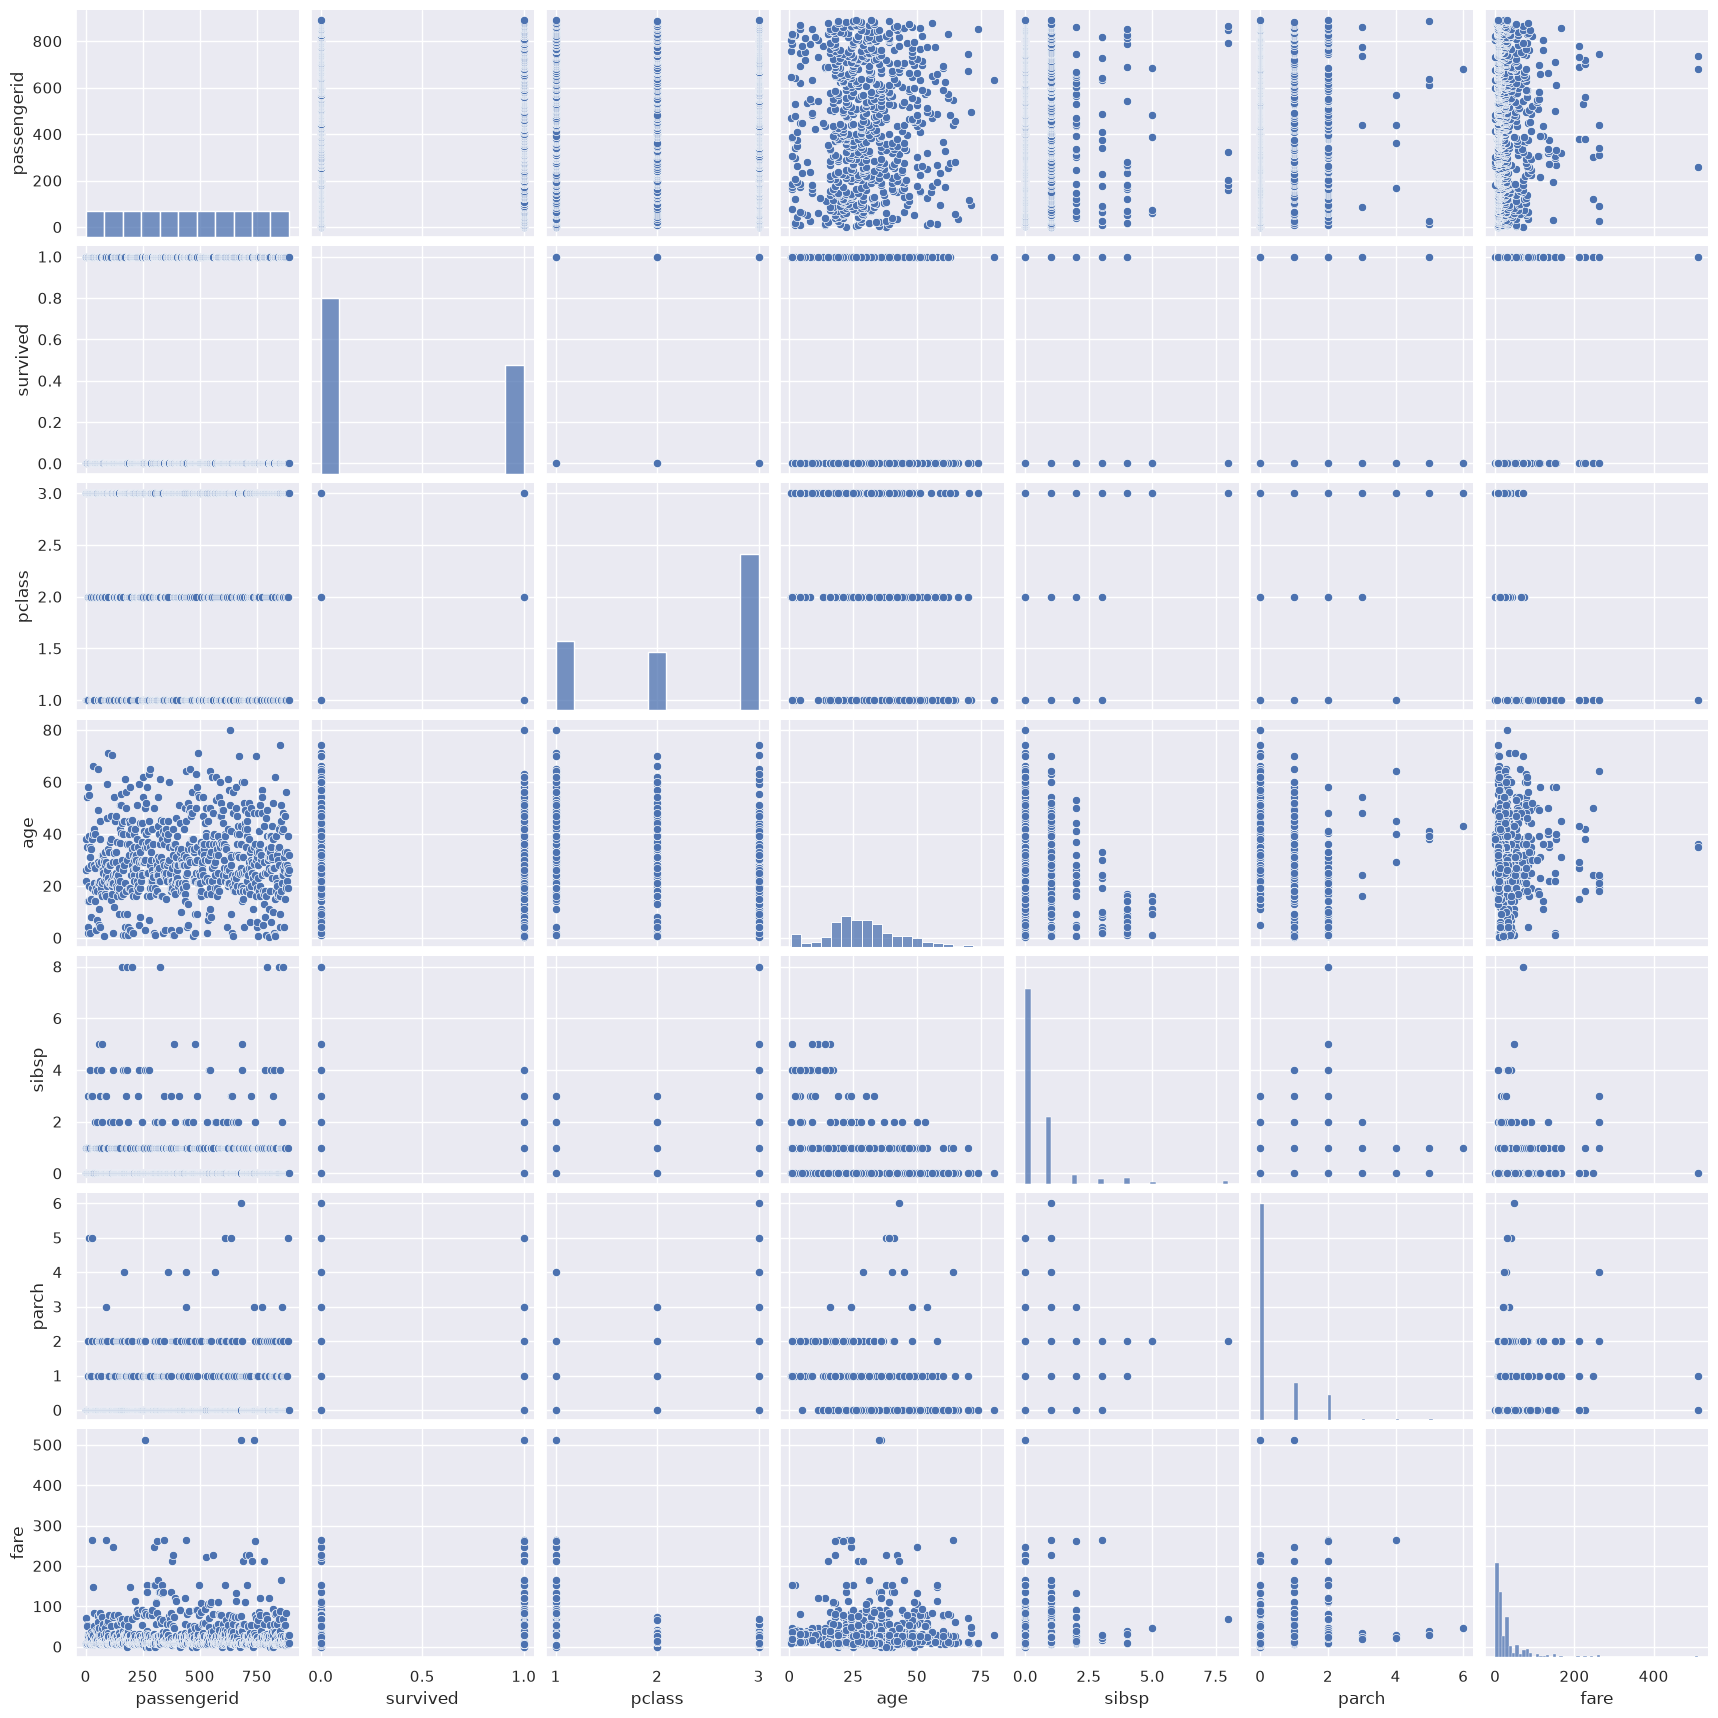

In [6]:
# 2. Visualize all the data using sns.pairplot.

sns.pairplot(titanic)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Check for null values.</span></p>
</div>


In [7]:
# 3. Check for null values.
titanic.isnull().sum()

passengerid      0
survived         0
pclass           0
name             0
sex              0
age            177
sibsp            0
parch            0
ticket           0
fare             0
cabin          687
embarked         2
dtype: int64

## #2 Select and Engineer Features

1. Fill age null values with -999.
2. Convert to numerical values if needed be by using `pd.get_dummies()`.
3. Create a list of the features you are going to use.  In this case use as many or as little as you would like.
4. Define our `X` and `y`.
5. Split our data into trainig and testing sets.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Fill age null values with -999.</span></p>
</div>


In [9]:
# 1. Fill age null values with -999.
titanic['age'] = titanic['age'].fillna(-999)
titanic.isnull().sum()

passengerid      0
survived         0
pclass           0
name             0
sex              0
age              0
sibsp            0
parch            0
ticket           0
fare             0
cabin          687
embarked         2
dtype: int64

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Convert to numerical values if needed be by using `pd.get_dummies()`.</span></p>
</div>


In [10]:
# 2. Convert to numerical values if needed be by using `pd.get_dummies()`.
titanic = pd.get_dummies(titanic, drop_first=True, dtype=int)
titanic.head()

,passengerid,survived,pclass,age,sibsp,parch,fare,"name_Abbott, Mr. Rossmore Edward","name_Abbott, Mrs. Stanton (Rosa Hunt)","name_Abelson, Mr. Samuel",...,cabin_F G63,cabin_F G73,cabin_F2,cabin_F33,cabin_F38,cabin_F4,cabin_G6,cabin_T,embarked_Q,embarked_S
0,1,0,3,22.0,1,0,7.2500,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,2,1,1,38.0,1,0,71.2833,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,1,3,26.0,0,0,7.9250,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,4,1,1,35.0,1,0,53.1000,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,5,0,3,35.0,0,0,8.0500,0,0,0,...,0,0,0,0,0,0,0,0,0,1


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> Print/Display/Return the first 5 rows of the file titanic.csv to see the data and selected features.</span></p>
</div>


In [11]:
# Print/Display/Return the first 5 rows of the file titanic.csv to see the data and selected features.
titanic.head()

,passengerid,survived,pclass,age,sibsp,parch,fare,"name_Abbott, Mr. Rossmore Edward","name_Abbott, Mrs. Stanton (Rosa Hunt)","name_Abelson, Mr. Samuel",...,cabin_F G63,cabin_F G73,cabin_F2,cabin_F33,cabin_F38,cabin_F4,cabin_G6,cabin_T,embarked_Q,embarked_S
0,1,0,3,22.0,1,0,7.2500,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,2,1,1,38.0,1,0,71.2833,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,1,3,26.0,0,0,7.9250,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,4,1,1,35.0,1,0,53.1000,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,5,0,3,35.0,0,0,8.0500,0,0,0,...,0,0,0,0,0,0,0,0,0,1


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Create a list of the features we are going to use.</span></p>
</div>


In [12]:
# 3. Create a list of the features we are going to use.
features = ['pclass', 'sex_male', 'age', 'sibsp', 'parch', 'fare', 'embarked_Q', 'embarked_S']

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Define our `X` and `y`. The target column for `y` is `survived`.</span></p>
</div>


In [13]:
# 4. Define our `X` and `y`.
X = titanic[features]
y = titanic['survived']

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Split our data into trainig and testing sets.</span></p>
</div>


In [14]:
# 5. Split our data into trainig and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## #3 Build and Train Model

1. For our first pass, initialize our model with `max_depth=2`.
2. Fit our model with our training data. 
3. Make predictions of our testing data.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. For our first pass, initialize our model with `max_depth=2`.</span></p>
</div>


In [15]:
# 1. For our first pass, initialize our model with `max_depth=2`.

dtree = DecisionTreeClassifier(max_depth=2)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Fit our model with our training data.</span></p>
</div>


In [16]:
# 2. Fit our model with our training data. 
dtree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Make predictions of our testing data.</span></p>
</div>


In [18]:
# 3. Make predictions of our testing data. 
y_pred = dtree.predict(X_test)
y_pred

array([0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 0])

## #4 Evaluate Model

1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores. 
    * To calculate auc score you have to get the predicted probabilites for the Survived class using `model.predict_proba(X_test)[:,1]`
2. Visualize our Decision Tree using provided code.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores.<br>Calculate predicted probabilities.<br>Keep only the probabilities for True.<br>Compute auc score.</span></p>
</div>


In [19]:
# 1. Evaluate and print our model scores using accuracy, precision, recall, f1 scores, and auc scores.
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

# Calculate predicted probabilities.
y_pred_proba = dtree.predict_proba(X_test)

# Keep only the probabilities for True.
y_pred_proba = y_pred_proba[:, 1]

# Compute auc score.
print("AUC:", roc_auc_score(y_test, y_pred_proba))

Accuracy: 0.7653631284916201
Precision: 0.9
Recall: 0.4864864864864865
F1 Score: 0.631578947368421
AUC: 0.8473616473616474


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


In [22]:
!sudo apt-get update
!sudo apt-get install -y graphviz

Get:1 https://packages.microsoft.com/repos/microsoft-ubuntu-noble-prod noble InRelease [3600 B]
Get:2 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble InRelease [256 kB]                
Get:4 https://packages.microsoft.com/repos/microsoft-ubuntu-noble-prod noble/main all Packages [640 B]
Get:5 https://packages.microsoft.com/repos/microsoft-ubuntu-noble-prod noble/main amd64 Packages [748 kB]
Get:6 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1557 kB]
Get:7 http://security.ubuntu.com/ubuntu noble-security/multiverse amd64 Packages [55.6 kB]
Get:8 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2137 kB]
Get:9 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1427 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]       
Get:11 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:12 http://archive.ubuntu.c

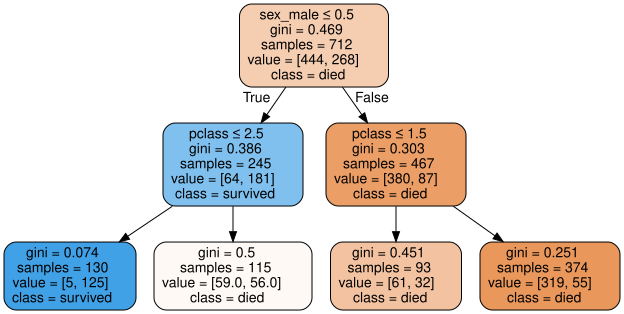

In [23]:
# 2. Visualize your decision tree.

dot_data = tree.export_graphviz(dtree, out_file=None, 
                     feature_names=features,
                     class_names=['died','survived'],
                     filled=True, rounded=True,  
                     special_characters=True)
graph = graphviz.Source(dot_data)
graph


## Picking the right parameters...

## Parameter tuning of your Decision Tree using GridSearch

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 
5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
6. Visualize your best tree.
7. Which feature was your most important feature?

```python
tree.DecisionTreeClassifier(
    *,
    criterion='gini',
    splitter='best',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features=None,
    random_state=None,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    min_impurity_split=None,
    class_weight=None,
    presort='deprecated',
    ccp_alpha=0.0,
)
```


[Tips on how to customize / set the paramters in the decision tree.](https://scikit-learn.org/stable/modules/tree.html#tips-on-practical-use)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [24]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.

param_grid = {
    'max_depth': [2, 4, 6],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [25]:
# 2. Initalize your GridSearchCV with a DecisionTreeClassifier, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5
)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [26]:
# 3. Fit your GridSearchCV with your training data. 
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 4, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defaul

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [27]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.
print(grid_search.best_params_)

{'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 5}


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [29]:
# 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 

# This command gives you the best Tree.
best_tree = grid_search.best_estimator_
y_pred_best = best_tree.predict(X_test)
y_pred_proba_best = best_tree.predict_proba(X_test)[:, 1]

# Now lets evaluate our model.
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1 Score:", f1_score(y_test, y_pred_best))
print("AUC:", roc_auc_score(y_test, y_pred_proba_best))

# Calculate predicted probabilities, keep only probability for when class = 1.
y_pred_proba_best = best_tree.predict_proba(X_test)[:, 1]

Accuracy: 0.8156424581005587
Precision: 0.847457627118644
Recall: 0.6756756756756757
F1 Score: 0.7518796992481203
AUC: 0.8522522522522523


<div style="background-color:#EAF3FB; color:#1a1a1a !important; border-left:6px solid #2471A3; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#2471A3 !important;">Provided.</b> <span style="color:#1a1a1a !important;"> Run this provided code.</span></p>
</div>


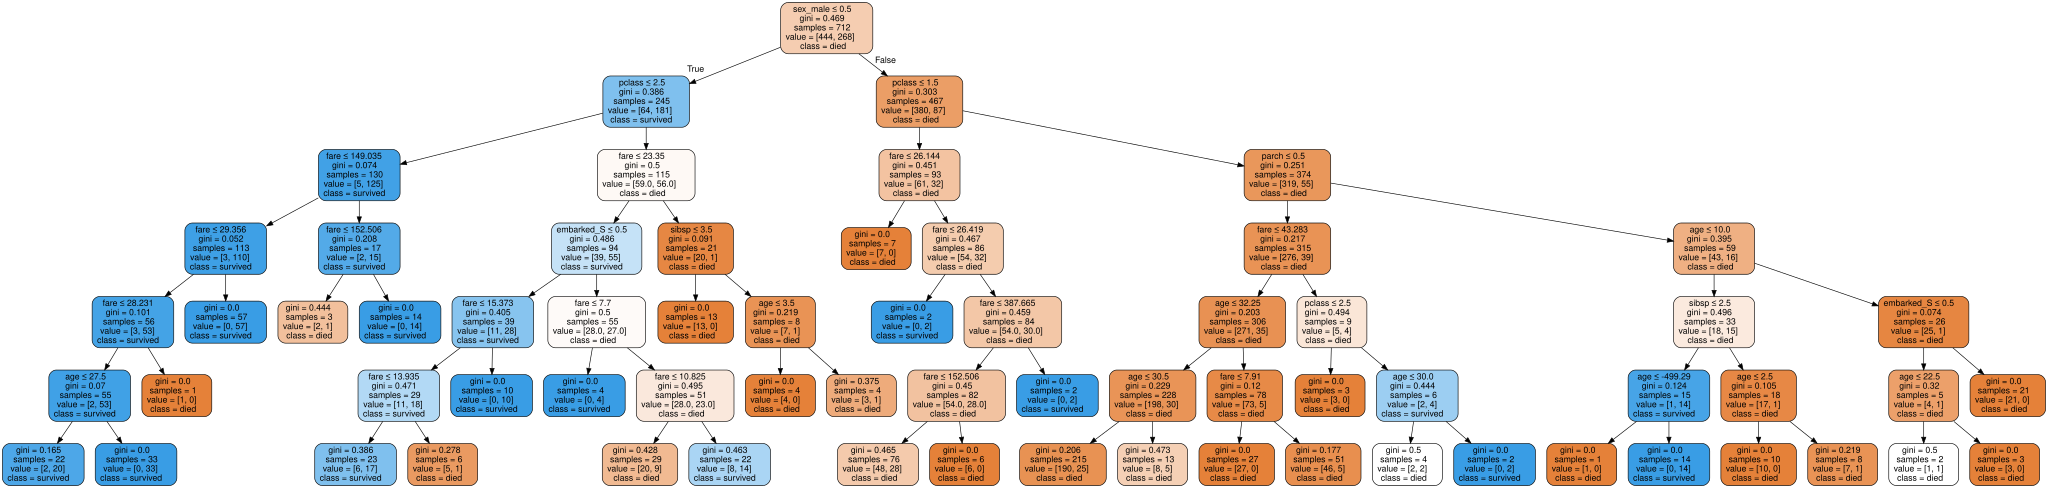

In [30]:
# 6. Visualize your best tree.

dot_data = tree.export_graphviz(best_tree, out_file=None, 
                     feature_names=features,
                     class_names=['died','survived'],
                     filled=True, rounded=True,  
                     special_characters=True)
graph = graphviz.Source(dot_data)
graph

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 7. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [31]:
# 7. Which feature was your most important feature?
#    Now lets look at our feature importances.

importances = best_tree.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
})

feature_importance.sort_values(by='Importance', ascending=False)

,Feature,Importance
1,sex_male,0.502641
0,pclass,0.179576
5,fare,0.170897
3,sibsp,0.065394
2,age,0.056722
7,embarked_S,0.013709
4,parch,0.011060
6,embarked_Q,0.000000


***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
<p style="text-align:center;">Write your answer in this cell after the table above.</p>


The feature that was my most important feature was sex_male, with an importance of 0.502641, which was much higher than the importance of any of the other features. The second most important feature is way behind, with an importance of only 0.179576. 

## Now onto Random Forests...
### We are going to do the same, but this time with a Random Forest. Remeber... Repetition is the father of learning.

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 
5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
6. Which feature was your most important feature?


## Parameters of the Random Forest Classifier

```python
RandomForestClassifier(
    n_estimators=100,
    *,
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features='auto',
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    min_impurity_split=None,
    bootstrap=True,
    oob_score=False,
    n_jobs=None,
    random_state=None,
    verbose=0,
    warm_start=False,
    class_weight=None,
    ccp_alpha=0.0,
    max_samples=None,
)
```

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [32]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 

rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [2, 4, 6],
    'min_samples_split': [2, 5, 10]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [33]:
# 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.

rf_grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [34]:
# 3. Fit your GridSearchCV with your training data.
rf_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 4, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [35]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.
print(rf_grid_search.best_params_)

{'max_depth': 6, 'min_samples_split': 5, 'n_estimators': 50}


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [38]:
# 5. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 

# This command gives you tree that has the highest f1-score.
best_rf = rf_grid_search.best_estimator_

y_pred_rf = best_rf.predict(X_test)

# Calculate predicted probabilities, keep only probability for when class = 1.
y_pred_proba_rf = best_rf.predict_proba(X_test)
y_pred_proba_rf = y_pred_proba_rf[:, 1]

# Now lets evaluate our model.
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("AUC:", roc_auc_score(y_test, y_pred_proba_rf))



Accuracy: 0.8100558659217877
Precision: 0.8448275862068966
Recall: 0.6621621621621622
F1 Score: 0.7424242424242424
AUC: 0.8915057915057915


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 6. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [39]:
# 6. Which feature was your most important feature?
#    Now lets look at our feature importances.

rf_importances = best_rf.feature_importances_

rf_feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_importances
})

rf_feature_importance.sort_values(by='Importance', ascending=False)

,Feature,Importance
1,sex_male,0.415345
5,fare,0.207336
0,pclass,0.132248
2,age,0.102108
3,sibsp,0.051035
4,parch,0.047453
7,embarked_S,0.030960
6,embarked_Q,0.013514


***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
<p style="text-align:center;">Write your answer in this cell after the table above.</p>


The feature that was my most important feature this time was still sex_male, although its importance is slightly lower than it was previously, with an importance of 0.415345. There is also a bit less of a gap between the importance of the rest of the features and the most important feature, with the runner up to sex_male having an importance of 0.207336. 

## Build a Random Forest using the ny-vs-sf-houses.csv data.

* Your target variable, aka the column you are trying to predict, aka your `y` variable is `in_sf`. 
* Can you get an accuracy above 88.8889%?
* What was your most important feature?


***
<h1 align="center"> <span style="color:#FF0000"> BUILD, TRAIN, AND EVAULATE A RANDOM FOREST MODEL BELOW. </span> </h1>

***


<h2 align="center"> Remember our main steps motto "ISBE". </h2>

<h3 align="center"> Main Steps when building a Machine Learning Model. </h3>
    
1. <b>I</b> - Inspect and explore data.
2. <b>S</b> - Select and engineer features.
3. <b>B</b> - Build and train model.
4. <b>E</b> - Evaluate model.


## #1 Inspect and Explore Data

1. Load ny-vs-sf-houses data.
2. Visualize all the data using sns.pairplot.
3. Check for null values.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Load in the ny-vs-sf-houses data set.<br>Read the file ny-vs-sf-houses.csv located inside the data folder and then load the data.<br>Print/Display/Return the first 5 rows of the file ny-vs-sf-houses.csv to make sure the file was loaded successfully.</span></p>
</div>


In [40]:
# 1. Load in the ny-vs-sf-houses data set.
#    Read the file ny-vs-sf-houses.csv located inside the data folder and then load the data.
houses = pd.read_csv('/workspaces/ds-fall-2026/Week-09-Trees/data/ny-vs-sf-houses.csv')

# Print/Display/Return the first 5 rows of the file ny-vs-sf-houses.csv to make sure the file was loaded successfully.
houses.head()

,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
0,0,2.0,1.0,999000,1960,1000,999,10
1,0,2.0,2.0,2750000,2006,1418,1939,0
2,0,2.0,2.0,1350000,1900,2150,628,9
3,0,1.0,1.0,629000,1903,500,1258,9
4,0,0.0,1.0,439000,1930,500,878,10


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Visualize all the data using sns.pairplot.</span></p>
</div>


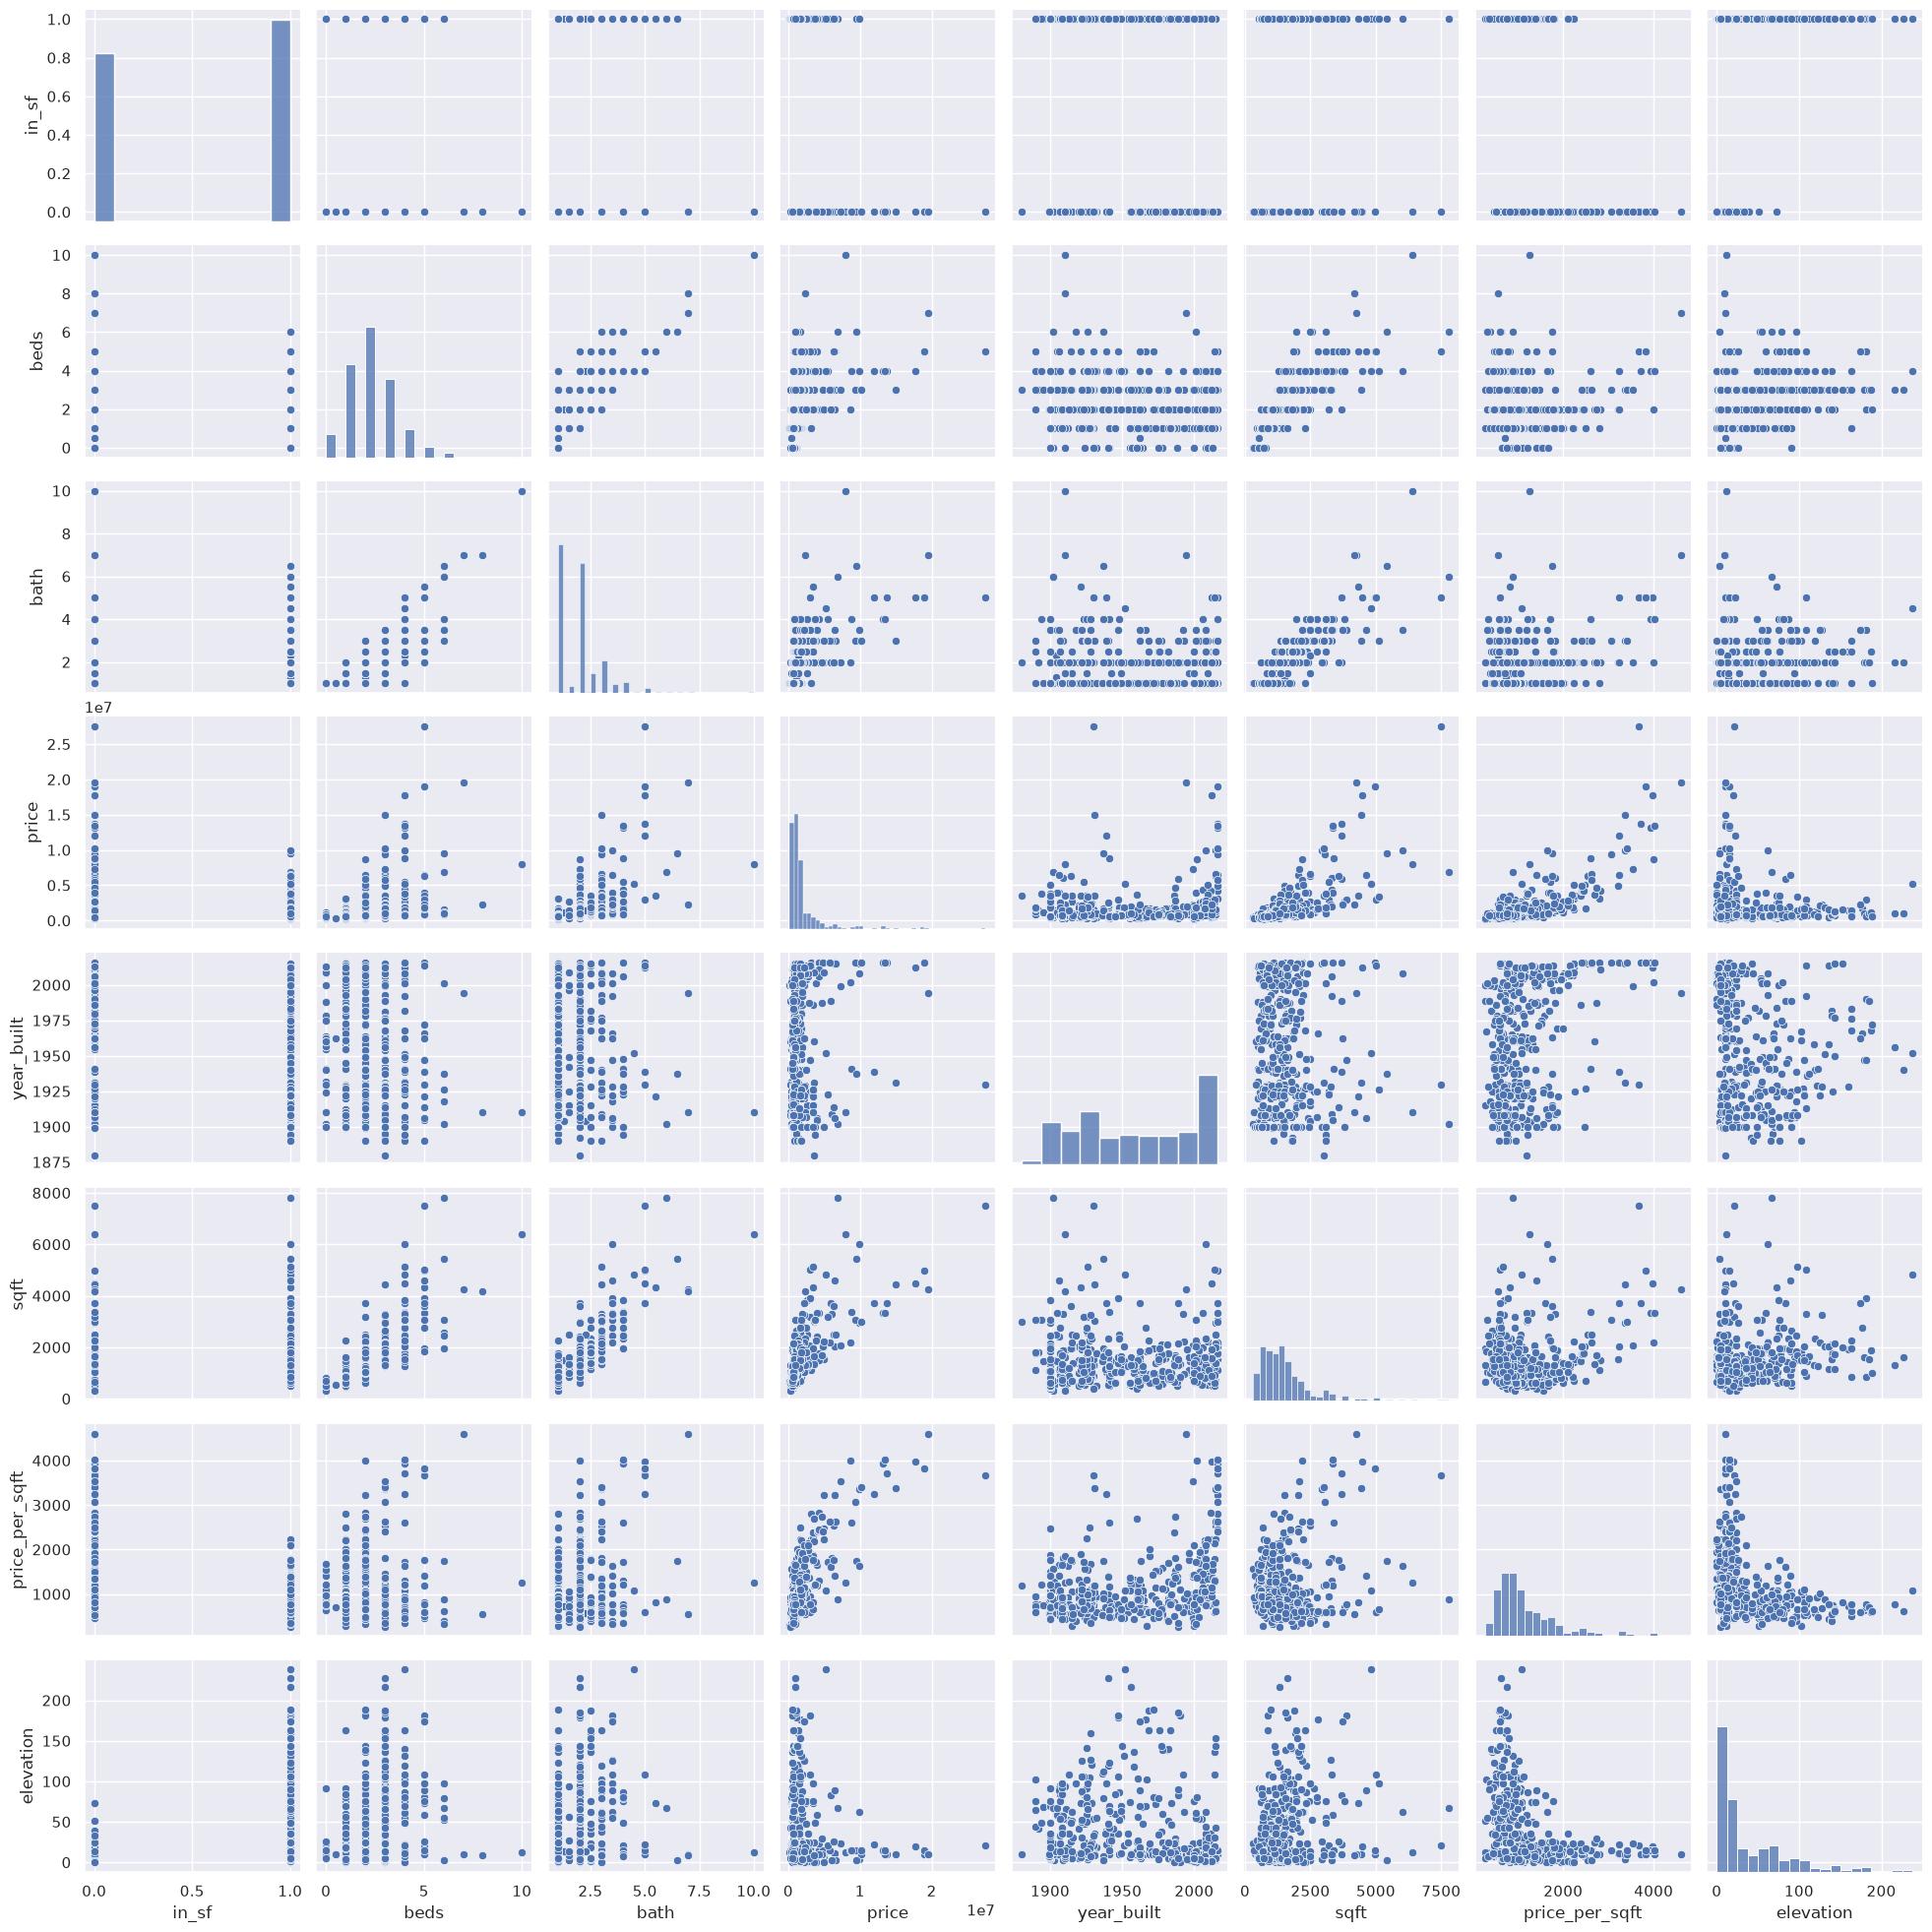

In [41]:
# 2. Visualize all the data using sns.pairplot.
sns.pairplot(houses)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Check for null values.</span></p>
</div>


In [42]:
# 3. Check for null values.
houses.isnull().sum()

in_sf             0
beds              0
bath              0
price             0
year_built        0
sqft              0
price_per_sqft    0
elevation         0
dtype: int64

## #2 Select and Engineer Features

1. Create a list of the features you are going to use.  In this case use as many or as little as you would like.
2. Define our `X` and `y`.
3. Split our data into trainig and testing sets.


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Create a list of the features you are going to use.<br>2. Define our `X` and `y`.<br>3. Split our data into trainig and testing sets.</span></p>
</div>


In [43]:
houses.dtypes

in_sf               int64
beds              float64
bath              float64
price               int64
year_built          int64
sqft                int64
price_per_sqft      int64
elevation           int64
dtype: object

In [44]:
# 1. Create a list of the features you are going to use.
features = ['beds', 'bath', 'price', 'year_built', 'sqft',
            'price_per_sqft', 'elevation']

# 2. Define our `X` and `y`.
X = houses[features]
y = houses['in_sf']

# 3. Split our data into trainig and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## #3 Build and Train Model

1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 
2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.  Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.
3. Fit your GridSearchCV with your training data. 
4. Print the parameters of your best model. 


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search.</span></p>
</div>


In [45]:
# 1. Make a dictionary of at least 3 parameters and a list of 3 values for each for your grid search. 

rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.<br>Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.</span></p>
</div>


In [46]:
# 2. Initialize your GridSearchCV with a RandomForestClassifer, your param_grid, and what you are optimizing for.
#    Choose any of the five optimization strategies; accuracy, precision, recall, f1, or roc_auc.

rf_grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 3. Fit your GridSearchCV with your training data.</span></p>
</div>


In [47]:
# 3. Fit your GridSearchCV with your training data.
rf_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=

<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 4. Print the parameters of your best model.<br>Print the best parameters it found.</span></p>
</div>


In [48]:
# 4. Print the parameters of your best model. 
#    Print the best parameters it found.

print(rf_grid_search.best_params_)

{'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}


## #4 Evaluate Model

1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 
2. Which feature was your most important feature?


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores.<br>What do you expect the best model from your search to be, and what will you try so you can evaluate it?<br>Now lets evaluate our model.<br>Calculate predicted probabilities, keep only probability for when class = 1.</span></p>
</div>


In [49]:
# 1. Evaluate your best model using accuracy, precision, recall, f1 scores, and auc scores. 

# This command gives you tree that has the highest f1-score.

best_rf = rf_grid_search.best_estimator_

y_pred_rf = best_rf.predict(X_test)

# Calculate predicted probabilities, keep only probability for when class = 1.

y_pred_proba_rf = best_rf.predict_proba(X_test)
y_pred_proba_rf = y_pred_proba_rf[:, 1]

# Now lets evaluate our model.

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("AUC:", roc_auc_score(y_test, y_pred_proba_rf))

Accuracy: 0.9090909090909091
Precision: 0.8983050847457628
Recall: 0.9464285714285714
F1 Score: 0.9217391304347826
AUC: 0.9647009966777409


<div style="background-color:#FFF8E7; color:#1a1a1a !important; border-left:6px solid #E67E22; padding:8px 14px; margin:8px 0;">
<p style="margin:0; color:#1a1a1a !important;"><b style="color:#E67E22 !important;">Your turn.</b> <span style="color:#1a1a1a !important;"> 2. Which feature was your most important feature?<br>Now lets look at our feature importances.</span></p>
</div>


In [50]:
# 2. Which feature was your most important feature?
#    Now lets look at our feature importances.
rf_importances = best_rf.feature_importances_

rf_feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_importances
})

rf_feature_importance.sort_values(by='Importance', ascending=False)

,Feature,Importance
6,elevation,0.345448
5,price_per_sqft,0.240350
2,price,0.124601
3,year_built,0.107991
4,sqft,0.107182
0,beds,0.045622
1,bath,0.028807


***
<h1 align="center"> <span style="color:#FFA500"> Which feature was your most important feature? </span> </h1>

***
<p style="text-align:center;">Write your answer in this cell after the table above.</p>


My most important feature was elevation, with an importance of 0.345448. This is lower than the other two models most important features. The other features had decently less importance, but not as much as the previous models.

# Awesome difficult extra credit below:
Build a classifier using the adult_income.csv data.  
* The target variable is 'class'.
* Start with just using these features `selected_features = ['age', 'fnlwgt', 'capital_gain', 'capital_loss', 'hours_per_week']`
* You have to include the pos_label in your precision, recall, and f1 scores. It just tells the classifier which one is the posotive label.  I provided the proper way below.

* See if you can get above 50% f1 score.  
* See some [super tricks and tips here](https://www.kaggle.com/code/jieyima/income-classification-model)